# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [46]:
ПІБ = 'Савков Олександр'        # напр. 'Шевченко Тарас'
ГРУПА = 'ші-33'      # напр. 'КН-31'
ВАРІАНТ = 6     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [12]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 6 · Савков Олександр, ші-33, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            3    2        1       4    630
Столярний цех, год         4    2        2       1    391
Фарбувальний цех, год      3    5        1       2   1349
Такелаж, компл.            3    2        0       2    811
Ділянка добудови, год      6    4        6       3   1085

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     40   62       19      57

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Столярний цех, год
  ціна:   29.5 за одиницю
  обсяг:  до 268 одиниць


In [13]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 — символічна модель**

x₁, x₂, x₃, x₄ — випуск яхт Sting, Ray, Breaker, Marlin, шт./місяць.

`Z = 40·x₁ + 62·x₂ + 19·x₃ + 57·x₄ → max`

```
3·x₁ + 2·x₂ + 1·x₃ + 4·x₄ ≤ 630    склопластик, м²
4·x₁ + 2·x₂ + 2·x₃ + 1·x₄ ≤ 391    столярний цех, год
3·x₁ + 5·x₂ + 1·x₃ + 2·x₄ ≤ 1349   фарбувальний цех, год
3·x₁ + 2·x₂ + 0·x₃ + 2·x₄ ≤ 811    такелаж, компл.
6·x₁ + 4·x₂ + 6·x₃ + 3·x₄ ≤ 1085   ділянка добудови, год

x₁, x₂, x₃, x₄ ≥ 0
```

ліва частина кожного рядка — витрата ресурсу на обраний план, права — наявний запас. умова невід'ємності потрібна тому, що без неї розв'язувач призначить від'ємний випуск і «вивільнить» ним ресурс, чого фізично не буває.

### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**

запас — параметр, бо на момент розв'язання він заданий ззовні: обсяг закупівель, графік цеху і потужність обладнання вже зафіксовані, а обираємо ми лише випуск яхт. якби ресурс можна було докупити в будь-якій кількості, запас став би змінною — обмеження перетворилось би на `3·x₁ + 2·x₂ + 1·x₃ + 4·x₄ ≤ 630 + y` при `y ≥ 0`, а в цілі з'явилися б витрати `Z = 40·x₁ + 62·x₂ + 19·x₃ + 57·x₄ − ціна·y`.

зміст задачі при цьому міняється з «як найкраще використати наявне» на «скільки ще купити». саме таке рішення ухвалюється на етапі 6, але не переписуванням моделі, а через тіньову ціну, яку порівнюють із ціною постачальника.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [14]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН     = [0, 155.67, 0, 79.67]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 14192.33                  # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)


Excel: [0, 155.67, 0, 79.67] | прибуток 14192.33


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [15]:
res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * 4, method='highs')
план = res.x
прибуток = -res.fun
shadow = np.round(-res.ineqlin.marginals, 6) + 0.0
reduced = np.round(-res.lower.marginals, 6) + 0.0

print('прибуток %.4f' % прибуток)
pd.DataFrame({'випуск': план.round(4), 'зведена вартість': reduced}, index=вироби)

прибуток 14192.3333


,випуск,зведена вартість
Sting,0.0000,-75.333333
Ray,155.6667,0.000000
Breaker,0.0000,-34.333333
Marlin,79.6667,0.000000


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [16]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Склопластик, м² | 630.00 | 8.6667 | 630 | 670 | 239 |
| Столярний цех, год | 391.00 | 22.3333 | 391 | 134 | 233.5 |
| Фарбувальний цех, год | 937.67 | 0 | 1349 | 1E+30 | 411.33 |
| Такелаж, компл. | 470.67 | 0 | 811 | 1E+30 | 340.33 |
| Ділянка добудови, год | 861.67 | 0 | 1085 | 1E+30 | 223.33 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

у дефіциті склопластик і столярний цех, решта три ресурси в надлишку. ознака подвійна і має виконуватись одночасно: кінцеве значення дорівнює правій частині (630 = 630 і 391 = 391) і тіньова ціна строго більша за нуль, 8.6667 та 22.3333. у фарбувального цеху, такелажу й ділянки добудови лишається 411.33 год, 340.33 компл. і 223.33 год, тіньова ціна нульова, а допустиме збільшення нескінченне — скільки цього запасу не додавай, план не зрушить ні на яхту. вузьке місце виробництва саме склопластик і столярний цех, розширювати решту зараз безглуздо.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Sting | 0.00 | −75.3333 | 40 | 75.33 | 1E+30 |
| Ray | 155.6667 | 0 | 62 | 52.00 | 29.43 |
| Breaker | 0.00 | −34.3333 | 19 | 34.33 | 1E+30 |
| Marlin | 79.6667 | 0 | 57 | 67.00 | 26.00 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

не виробляються Sting і Breaker, у обох кінцеве значення нуль. у Breaker зведена вартість −34.3333: втиснута в план одна яхта зменшила б прибуток саме на цю суму, бо її ресурси вигідніше віддати під Ray і Marlin. щоб він увійшов у план, прибуток з одиниці має зрости з 19 до 53.3333 — число взято з колонки «зведена вартість» звіту, і воно ж стоїть у допустимому збільшенні цільового коефіцієнта Breaker, 34.33. у Sting та сама величина −75.3333, тобто з 40 до 115.3333, він ще далі від входження в план.

---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [35]:
i_res = int(np.argmax(shadow))
res_plus = linprog(-c, A_ub=A, b_ub=b + np.eye(len(b))[i_res],
                   bounds=[(0, None)] * 4, method='highs')
gain = -res_plus.fun - прибуток

print('%s: прибуток %.4f -> %.4f, приріст %.4f, тіньова ціна зі звіту %.4f'
      % (ресурси[i_res], прибуток, -res_plus.fun, gain, shadow[i_res]))

Столярний цех, год: прибуток 14192.3333 -> 14214.6667, приріст 22.3333, тіньова ціна зі звіту 22.3333


**Відповідь 5.1:**

збігається: запас столярного цеху 392 замість 391 дає прибуток 14214.6667 проти 14192.3333, тобто приріст рівно 22.3333, як і тіньова ціна зі звіту, розбіжність 3·10⁻⁷ це машинна похибка. план при цьому перебудувався, випуск Ray зріс а Marlin трохи впав — година сама по собі прибутку не додає, вона дозволяє перекласти план на вигідніший.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

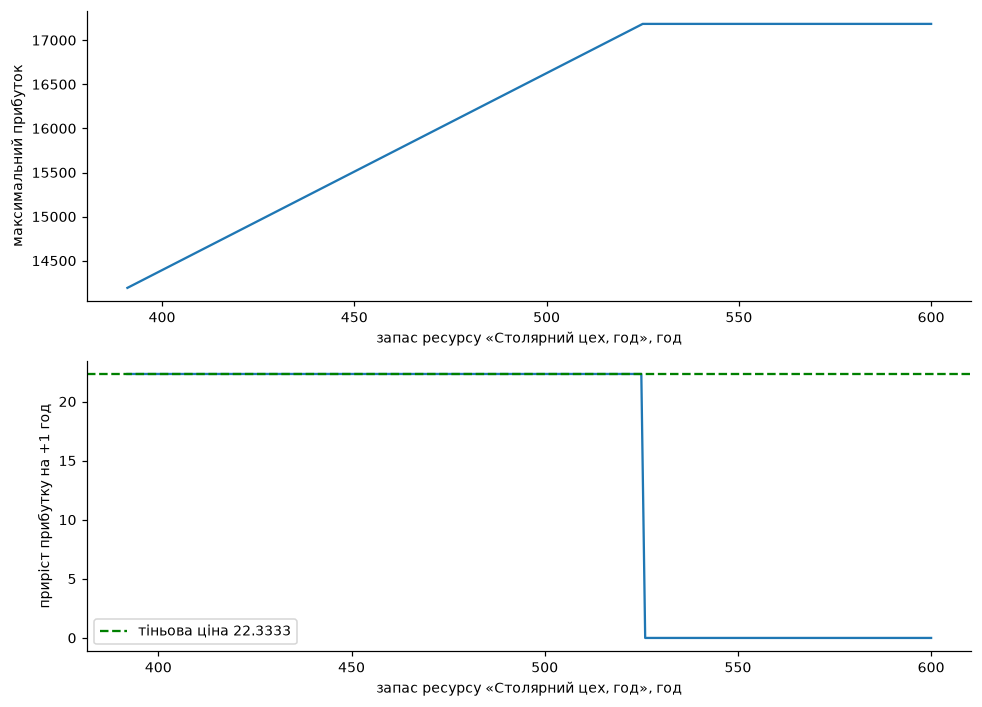

злам на індексі 134: запас 525, приріст падає з 22.3333 до 0.0000


In [33]:
stocks = np.arange(b[i_res], 601.0, 1.0)
profits = []
for s in stocks:
    bs = b.copy()
    bs[i_res] = s
    profits.append(-linprog(-c, A_ub=A, b_ub=bs, bounds=[(0, None)] * 4, method='highs').fun)
profits = np.array(profits)
steps = np.diff(profits)
kink = int(np.argmax(np.abs(steps - shadow[i_res]) > 1e-6))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.5))
ax1.plot(stocks, profits)
ax1.set_xlabel('запас ресурсу «%s», год' % ресурси[i_res])
ax1.set_ylabel('максимальний прибуток')
ax2.plot(stocks[1:], steps)
ax2.axhline(shadow[i_res], color='green', ls='--',
            label='тіньова ціна %.4f' % shadow[i_res])
ax2.set_xlabel('запас ресурсу «%s», год' % ресурси[i_res])
ax2.set_ylabel('приріст прибутку на +1 год')
ax2.legend()
plt.tight_layout()
plt.show()

print('злам на індексі %d: запас %.0f, приріст падає з %.4f до %.4f'
      % (kink, stocks[kink], steps[kink - 1], steps[kink]))

**Відповідь 5.2:**

збільшувати можна на 134 години, з 391 до 525, і доти кожна додає рівно 22.3333 — на нижньому графіку приріст лежить точно на лінії тіньової ціни. на 135-й годині приріст падає до нуля, бо вичерпується залишок ділянки добудови 223.33 год, вона стає новим вузьким місцем і столярний цех перестає бути дефіцитним. межа перевіряється алгеброю базису: додаткова година столярного цеху додає 0.6667 яхти Ray і віднімає 0.3333 Marlin, ділянка добудови витрачає на це 1.6667 год, тому запасу 223.33 вистачає рівно на 223.33 / 1.6667 = 134 години. перебір у Python дає те саме число.


---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [34]:
price = V['ціна_пропозиції']
offer = V['обсяг_пропозиції']
i_offer = V['ресурс_пропозиції']
limit = int(stocks[kink] - b[i_offer])

rows = []
for q in [1, 100, limit, offer]:
    bq = b.copy()
    bq[i_offer] += q
    gain_q = -linprog(-c, A_ub=A, b_ub=bq, bounds=[(0, None)] * 4, method='highs').fun - прибуток
    rows.append({'куплено': q, 'приріст прибутку': round(gain_q, 4),
                 'вартість': round(price * q, 4),
                 'чистий результат': round(gain_q - price * q, 4)})

print('%s: ціна %.1f, тіньова ціна %.4f, чистий виграш на одиницю %.4f, межа діапазону %d'
      % (ресурси[i_offer], price, shadow[i_offer], shadow[i_offer] - price, limit))
pd.DataFrame(rows)

Столярний цех, год: ціна 29.5, тіньова ціна 22.3333, чистий виграш на одиницю -7.1667, межа діапазону 134


,куплено,приріст прибутку,вартість,чистий результат
0,1,22.3333,29.5,-7.1667
1,100,2233.3333,2950.0,-716.6667
2,134,2992.6667,3953.0,-960.3333
3,268,2992.6667,7906.0,-4913.3333


**Відповідь 6.1:**

не брати: година столярного цеху коштує 29.5, а варта 22.3333, кожна куплена година дає мінус 7.1667. навіть за вигідної ціни купувати мало б сенс не більше 134 годин, бо далі тіньова ціна падає до нуля, вузьким місцем стає ділянка добудови і приріст прибутку на 134 та на 268 годинах однаковий, 2992.67. пряма перевірка це підтвердила: при 268 куплених годинах чистий результат від'ємний, −4913.33, а на найвигідніших 134 годинах усе одно −960.33.

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [20]:
tol = 1e-6
used = A @ план
ненульових = int(np.sum(план > tol))
звязних = int(np.sum(np.abs(used - b) < tol))

print('ненульових змінних %d, зв’язних обмежень %d' % (ненульових, звязних))
pd.DataFrame({'витрачено': used.round(4), 'запас': b,
              'залишок': (b - used).round(4)}, index=ресурси)

ненульових змінних 2, зв’язних обмежень 2


,витрачено,запас,залишок
"Склопластик, м²",630.0000,630.0,0.0000
"Столярний цех, год",391.0000,391.0,0.0000
"Фарбувальний цех, год",937.6667,1349.0,411.3333
"Такелаж, компл.",470.6667,811.0,340.3333
"Ділянка добудови, год",861.6667,1085.0,223.3333


In [47]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:**

збіглися: ненульових змінних 2, Ray і Marlin, зв'язних обмежень теж 2, склопластик і столярний цех. так і має бути, бо вершина в просторі чотирьох змінних задається чотирма активними умовами: дві з них рівності x_Sting = 0 і x_Breaker = 0, ще дві зв'язні ресурсні обмеження.

розбіжність означала б вироджений розв'язок — у вершині перетинається більше обмежень, ніж потрібно для її визначення. на практиці тоді тіньова ціна перестає бути однозначною, допустиме збільшення може виявитись нульовим, а два розв'язувачі законно повертають різні набори тіньових цін при однаковому плані й однаковій цілі. саме це станеться в частині 2.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [36]:
plan_floor = np.floor(план + tol)
plan_int = np.round(linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * 4,
                            method='highs', integrality=np.ones(4)).x)
variants = [план, plan_floor, plan_int]

tab = pd.DataFrame(variants, columns=вироби,
                   index=['дробовий', 'округлений униз', 'цілочисельний']).round(4)
tab['прибуток'] = [round(float(c @ x), 4) for x in variants]
tab['допустимий'] = [bool(np.all(A @ x <= b + tol)) for x in variants]

print('округлення вниз втрачає %.0f прибутку проти цілого оптимуму'
      % float(c @ plan_int - c @ plan_floor))
tab

округлення вниз втрачає 62 прибутку проти цілого оптимуму


,Sting,Ray,Breaker,Marlin,прибуток,допустимий
дробовий,0.0,155.6667,0.0,79.6667,14192.3333,True
округлений униз,0.0,155.0000,0.0,79.0000,14113.0000,True
цілочисельний,0.0,156.0000,0.0,79.0000,14175.0000,True


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | Sting 0, Ray 155.6667, Breaker 0, Marlin 79.6667 | 14192.3333 | так, але фізично нездійсненний |
| округлений | Sting 0, Ray 155, Breaker 0, Marlin 79 | 14113.00 | так |
| цілочисельний оптимум | Sting 0, Ray 156, Breaker 0, Marlin 79 | 14175.00 | так |

**Висновок:** округлювати не можна: план 155 і 79 допустимий, жодне обмеження не порушено, але дає 14113 проти 14175 у цілочисельного оптимуму, тобто 62 одиниці прибутку на рівному місці. гірше те, що округлення рухає план не в той бік — цілий оптимум має Ray 156, більше ніж дробові 155.6667, тож правило «відкинути дробову частину» вгадало б хіба випадково. округлений розв'язок дає лише нижню оцінку цілого оптимуму, дробовий верхню: 14113 ≤ 14175 ≤ 14192.33.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [38]:
постачальники = ['Суми', 'Апостолове', 'Вінниця']
споживачі     = ['Одеса', 'Львів', 'Енергодар', 'Київ']
D = np.array([[800., 900., 600., 330.],
              [330., 900., 120., 450.],
              [430., 360., 620., 270.]])
запас = [50, 40, 30]
попит = [25, 35, 30, 30]

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'

print('відстані автошляхами з Google Maps, округлені до 10 км; запас %d = попит %d'
      % (sum(запас), sum(попит)))
pd.DataFrame(D, index=постачальники, columns=споживачі)

відстані автошляхами з Google Maps, округлені до 10 км; запас 120 = попит 120


,Одеса,Львів,Енергодар,Київ
Суми,800.0,900.0,600.0,330.0
Апостолове,330.0,900.0,120.0,450.0
Вінниця,430.0,360.0,620.0,270.0


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [24]:
prob = pulp.LpProblem('transport', pulp.LpMinimize)
x = {(i, j): pulp.LpVariable('x_%d_%d' % (i, j), lowBound=0)
     for i in range(3) for j in range(4)}
prob += pulp.lpSum(D[i, j] * x[i, j] for i in range(3) for j in range(4))
names = ['supply_%d' % i for i in range(3)] + ['demand_%d' % j for j in range(4)]
for i in range(3):
    prob += pulp.lpSum(x[i, j] for j in range(4)) == запас[i], names[i]
for j in range(4):
    prob += pulp.lpSum(x[i, j] for i in range(3)) == попит[j], names[3 + j]
prob.solve(pulp.PULP_CBC_CMD(msg=0))

plan_pulp = np.array([[x[i, j].value() for j in range(4)] for i in range(3)])
pi_pulp = np.array([prob.constraints[n].pi for n in names])

print('pulp: вартість %.0f, тіньові ціни %s' % (pulp.value(prob.objective), pi_pulp))
pd.DataFrame(plan_pulp, index=постачальники, columns=споживачі)

pulp: вартість 44100, тіньові ціни [ 540.   70.    0.  260.  360.   50. -210.]


,Одеса,Львів,Енергодар,Київ
Суми,15.0,5.0,0.0,30.0
Апостолове,10.0,0.0,30.0,0.0
Вінниця,0.0,30.0,0.0,0.0


In [27]:
A_eq = np.zeros((7, 12))
for i in range(3):
    A_eq[i, i * 4:(i + 1) * 4] = 1.0
for j in range(4):
    A_eq[3 + j, j::4] = 1.0
b_eq = np.array(list(запас) + list(попит), float)

res_tr = linprog(D.flatten(), A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)] * 12, method='highs')
plan_tr = res_tr.x.reshape(3, 4)
pi_scipy = res_tr.eqlin.marginals

print('scipy: вартість %.0f, тіньові ціни %s' % (res_tr.fun, pi_scipy))
pd.DataFrame(plan_tr.round(6), index=постачальники, columns=споживачі)

scipy: вартість 44100, тіньові ціни [  -0. -470. -540.  800.  900.  590.  330.]


,Одеса,Львів,Енергодар,Київ
Суми,15.0,5.0,0.0,30.0
Апостолове,10.0,0.0,30.0,0.0
Вінниця,0.0,30.0,0.0,0.0


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [28]:
shift_sup = pi_scipy[:3] - pi_pulp[:3]
shift_con = pi_scipy[3:] - pi_pulp[3:]

print('вартість %.0f і %.0f, плани збігаються %s; зсув по постачальниках %s, по споживачах %s'
      % (pulp.value(prob.objective), res_tr.fun, np.allclose(plan_pulp, plan_tr, atol=1e-6),
         shift_sup, shift_con))
pd.DataFrame({'pulp': pi_pulp, 'scipy': pi_scipy, 'scipy − pulp': pi_scipy - pi_pulp},
             index=['запас: ' + s for s in постачальники] +
                   ['попит: ' + s for s in споживачі])

вартість 44100 і 44100, плани збігаються True; зсув по постачальниках [-540. -540. -540.], по споживачах [540. 540. 540. 540.]


,pulp,scipy,scipy − pulp
запас: Суми,540.0,-0.0,-540.0
запас: Апостолове,70.0,-470.0,-540.0
запас: Вінниця,0.0,-540.0,-540.0
попит: Одеса,260.0,800.0,540.0
попит: Львів,360.0,900.0,540.0
попит: Енергодар,50.0,590.0,540.0
попит: Київ,-210.0,330.0,540.0


**Відповідь 10.2:**

вартість однакова, 44100 в обох, плани перевезень теж збіглися повністю, а тіньові ціни різні: pulp дав (540, 70, 0 | 260, 360, 50, −210), scipy — (0, −470, −540 | 800, 900, 590, 330), не збіглося жодне з семи чисел. закономірність стала і протилежна за знаком у двох групах: у всіх трьох постачальників scipy − pulp = −540, у всіх чотирьох споживачів +540, тобто u′ᵢ = uᵢ − k і v′ⱼ = vⱼ + k при k = 540, через що сума uᵢ + vⱼ для будь-якої пари не змінюється. причина в балансі: сумарний запас дорівнює сумарному попиту, 120 = 120, сума трьох рівнянь постачальників тотожна сумі чотирьох рівнянь споживачів, одне обмеження лінійно залежне, ранг 6 замість 7, і дуальні змінні визначені лише з точністю до адитивної константи, яку кожен розв'язувач нормує по-своєму.

для того, хто ухвалює рішення, це означає, що абсолютні тіньові ціни тут читати не можна: «запас у Сумах вартий 540» на іншій бібліотеці обертається нулем. змістовні тільки різниці — Суми мінус Вінниця 540 в обох розв'язувачах, Львів мінус Київ 570 в обох — і суми uᵢ + vⱼ, з яких рахується оцінка маршруту dᵢⱼ − uᵢ − vⱼ.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [48]:
nz_tr = int(np.sum(plan_tr > tol))
binding_tr = int(np.sum(np.abs(A_eq @ res_tr.x - b_eq) < tol))

print('ненульових перевезень %d, зв’язних обмежень %d з 7, ранг матриці обмежень %d'
      % (nz_tr, binding_tr, np.linalg.matrix_rank(A_eq)))
pd.DataFrame(np.where(plan_tr > tol, 'зайнятий', '—'),
             index=постачальники, columns=споживачі)

ненульових перевезень 6, зв’язних обмежень 7 з 7, ранг матриці обмежень 6


,Одеса,Львів,Енергодар,Київ
Суми,зайнятий,зайнятий,—,зайнятий
Апостолове,зайнятий,—,зайнятий,—
Вінниця,—,зайнятий,—,—


**Відповідь 11.1:**

ненульових перевезень 6, зв'язних обмежень 7, тобто всі. зв'язні всі тому, що обмеження записані рівностями: «відправити з Сум менше за 50» означало б залишок на складі, «привезти в Київ менше за 30» — необслуженого клієнта, і модель ні того, ні того не допускає, тож слаку тут не існує в принципі і підрахунок зв'язних нічого не повідомляє, відповідь 7 відома наперед. ненульових на одне менше, бо сумарний запас дорівнює попиту, одне з семи рівнянь лінійно залежне і ранг матриці обмежень 3 + 4 − 1 = 6 (порахований у клітинці вище), а базис опорного плану транспортної задачі містить рівно стільки клітинок.

перевірка «ненульових = зв'язних» з етапу 7 тут не працює і працювати не може: вона спиралась на незалежність обмежень і на те, що зайві не активні, а в транспортній задачі з балансом обидва припущення хибні.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

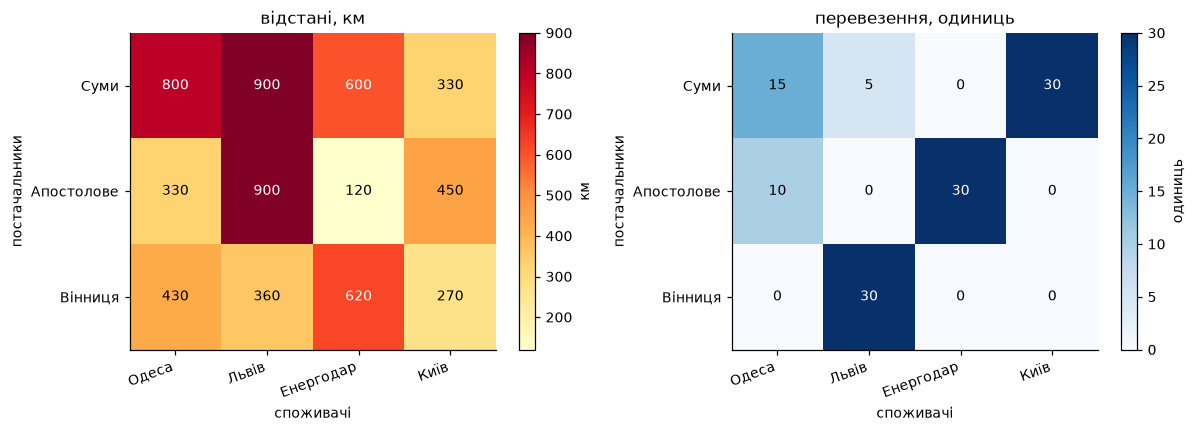

сумарний пробіг 44100 км·од.


In [40]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, M, cmap, title, unit in [(axes[0], D, 'YlOrRd', 'відстані', 'км'),
                                 (axes[1], plan_tr, 'Blues', 'перевезення', 'одиниць')]:
    im = ax.imshow(M, cmap=cmap, aspect='auto')
    ax.set_title('%s, %s' % (title, unit))
    ax.set_xticks(range(4))
    ax.set_xticklabels(споживачі, rotation=20, ha='right')
    ax.set_yticks(range(3))
    ax.set_yticklabels(постачальники)
    ax.set_xlabel('споживачі')
    ax.set_ylabel('постачальники')
    for i in range(3):
        for j in range(4):
            ax.text(j, i, '%.0f' % M[i, j], ha='center', va='center', fontsize=9,
                    color='white' if M[i, j] > M.max() * 0.6 else 'black')
    fig.colorbar(im, ax=ax, label=unit)
plt.tight_layout()
plt.show()

print('сумарний пробіг %.0f км·од.' % res_tr.fun)

**Висновок:** темні клітинки плану тяжіють до світлих клітинок відстаней, але збіг неповний — Суми везуть 15 одиниць на Одесу за 800 км і 5 на Львів за 900 км, бо дешевий для них напрямок на Київ уже вичерпано попитом у 30, а найкоротша пара Вінниця → Київ, 270 км, простоює: карти показують компроміс між відстанню і рамками запасів та попиту, а не «найближче до найближчого».

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [43]:
ІНСТРУМЕНТИ_ШІ = 'Claude'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'ні',
    'етап 2, побудова моделі в Excel':      'ні',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'синтаксис',
    'етап 6, рішення про закупівлю':        'код, перевірено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = ('звірив план і прибуток з Excel і Python, вони збіглися до сотих,  у транспортній задачі звірив вартість 44100 у двох розв\'язувачів і переконався, що різниця тіньових цін стала')
# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [44]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Савков Олександр
інструменти:                               Claude
------------------------------------------------------------------------------
етап 1, формалізація моделі:               ні
етап 2, побудова моделі в Excel:           ні
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     синтаксис
етап 6, рішення про закупівлю:             код, перевірено
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
звірив план і прибуток з Excel і Python, вони збіглися до сотих,  у транспортній задачі звірив вартість 44100 у двох розв'язувачів і переконався, що різниця тіньових цін стала


---
# Крок 13. Фінальна самоперевірка

In [45]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
